# Part 2: Single Stock Analysis
## Set up:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import scrapbook as sb
from contextlib import closing
from pathlib import Path
from IPython.display import display
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

volatility_window = 20

## 2.1 Parameters

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working copy of the database

In [3]:
# Parameters
ticker = "JPM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


## 2.2 Data Loading

In [4]:
database = Path(db_path).expanduser().resolve()
if not database.is_file():
    raise FileNotFoundError(f'{database} not found; run 01_data_cleaning.ipynb first.')

# check the date order:
if pd.Timestamp(start_date) > pd.Timestamp(end_date):
    raise ValueError('start_date must be on or before end_date.')

# load cleaned data
query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned WHERE ticker = ? AND ts >= ? AND ts <= ? ORDER BY ts
"""
with closing(sqlite3.connect(database.as_uri() + '?mode=ro', uri=True)) as conn:
    df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date), parse_dates=['ts'], index_col='ts')

# 20 returns need at least 21 prices
if len(df) < volatility_window + 1:
    raise ValueError(f'{ticker}: need at least {volatility_window + 1} prices for {volatility_window} returns; '
                     f'got {len(df)} between {start_date} and {end_date}.')

first_date, last_date = df.index.min().strftime('%Y-%m-%d'), df.index.max().strftime('%Y-%m-%d')
print(f'{ticker} from {start_date} to {end_date}: {len(df)} trading days')
print(f'Actual first observation: {first_date} | Actual last observation: {last_date}')
display(df.head())
display(df.tail())

JPM from 2024-06-01 to 2024-11-30: 97 trading days
Actual first observation: 2024-06-03 | Actual last observation: 2024-10-18


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,202.31,202.42,199.19,201.82,199.49,6444309
2024-06-04,200.16,201.98,198.28,199.16,196.86,6848338
2024-06-05,199.76,199.82,196.92,197.26,194.98,8351600
2024-06-06,197.26,198.02,195.33,196.91,194.63,7640300
2024-06-07,197.43,200.92,197.01,199.95,197.64,6964500


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,223.20,223.70,218.88,221.48,221.48,9048925
2024-10-15,223.66,225.45,221.82,222.39,222.39,9235825
2024-10-16,222.33,223.68,221.04,223.64,223.64,6382515
2024-10-17,224.27,225.85,223.31,224.42,224.42,6470186
2024-10-18,225.00,225.92,223.10,225.50,225.50,5364080


### Validate the input

`quality_flags` checks the loaded rows, and any flagged row stops the report.

In [5]:
def quality_flags(frame):
    """Flag missing/non-finite values, nonpositive equity prices, bad OHLC, and duplicate dates."""
    price_cols = ['open', 'high', 'low', 'close', 'adj_close']
    flags = pd.DataFrame(index=frame.index)
    flags['missing_or_nonfinite'] = ~np.isfinite(frame[price_cols + ['volume']]).all(axis=1)
    flags['nonpositive_price'] = frame[price_cols].le(0).any(axis=1)
    flags['ohlc_bounds'] = (frame['high'].lt(frame[['open', 'close']].max(axis=1))
                            | frame['low'].gt(frame[['open', 'close']].min(axis=1))
                            | frame['high'].lt(frame['low']))
    flags['negative_volume'] = frame['volume'].lt(0)
    flags['duplicate_date'] = frame.index.duplicated(keep=False)
    return flags

quality = quality_flags(df)
display(quality.sum().rename('rows flagged').to_frame())
if quality.any().any():
    raise ValueError('Data quality checks failed: ' + str(quality.sum().to_dict()))

,rows flagged
missing_or_nonfinite,0
nonpositive_price,0
ohlc_bounds,0
negative_volume,0
duplicate_date,0


## 2.3 Calculate Risk Metrics
Returns and drawdown use `adj_close`, so splits and dividends do not appear as losses. The rolling windows keep their warm-up values as NaN.

### Daily Returns

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns: log(P_t / P_t-1); the first value is NaN."""
    return np.log(prices / prices.shift(1))

### Rolling Volatility (20-day window)

In [7]:
def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility: sample std of a full window of returns x sqrt(252)."""
    return returns.rolling(window).std() * np.sqrt(252)

### Drawdown and Maximum Drawdown

In [8]:
def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak; its min() is the maximum drawdown."""
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max

### Sharpe Ratio
The ratio is undefined (shown as N/A) with fewer than two returns or zero volatility, rather than an infinite or misleading number.

In [9]:
def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio from daily log returns; NaN when undefined."""
    observed = returns.dropna()
    std_return = observed.std()
    if len(observed) < 2 or not np.isfinite(std_return) or np.isclose(std_return, 0):
        return np.nan
    return (observed.mean() * 252 - risk_free_rate) / (std_return * np.sqrt(252))

### Apply the functions

In [10]:
df['log_return'] = calculate_returns(df['adj_close'])
df['volatility'] = calculate_volatility(df['log_return'], volatility_window)
df['drawdown'] = calculate_max_drawdown(df['adj_close'])
df['sma_50'] = df['adj_close'].rolling(50).mean()
sharpe_ratio = calculate_sharpe_ratio(df['log_return'])

# checks: warm-up stays NaN then all finite, and zero volatility gives NaN Sharpe
assert df['volatility'].iloc[:volatility_window].isna().all()
assert np.isfinite(df['volatility'].iloc[volatility_window:]).all()
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01, 0.01])))

# the first full volatility window ends at the 21st price
metric_cols = ['adj_close', 'log_return', 'volatility', 'drawdown']
display(df[metric_cols].iloc[volatility_window - 2:volatility_window + 2])
display(df[metric_cols].tail())
print('Sharpe ratio:', 'N/A' if pd.isna(sharpe_ratio) else f'{sharpe_ratio:.2f}')
print(f"Maximum drawdown: {df['drawdown'].min():.2%} on {df['drawdown'].idxmin().date()}")
if df['sma_50'].isna().all():
    print(f'Only {len(df)} prices: the 50-day moving average needs 50, so it is not shown.')

,adj_close,log_return,volatility,drawdown
ts,,,,
2024-06-28,199.92,0.015374,NaN,0.00000
2024-07-01,203.07,0.015633,NaN,0.00000
2024-07-02,206.41,0.016314,0.195505,0.00000
2024-07-03,206.28,-0.000630,0.187653,-0.00063


,adj_close,log_return,volatility,drawdown
ts,,,,
2024-10-14,221.48,-0.003651,0.226438,-0.008728
2024-10-15,222.39,0.004100,0.226134,-0.004655
2024-10-16,223.64,0.005605,0.222014,0.000000
2024-10-17,224.42,0.003482,0.218808,0.000000
2024-10-18,225.50,0.004801,0.218840,0.000000


Sharpe ratio: 1.30
Maximum drawdown: -10.13% on 2024-08-05


## 2.4 Visualization
The footer shows the observed dates, because a ticker's data could end before the requested `end_date`.

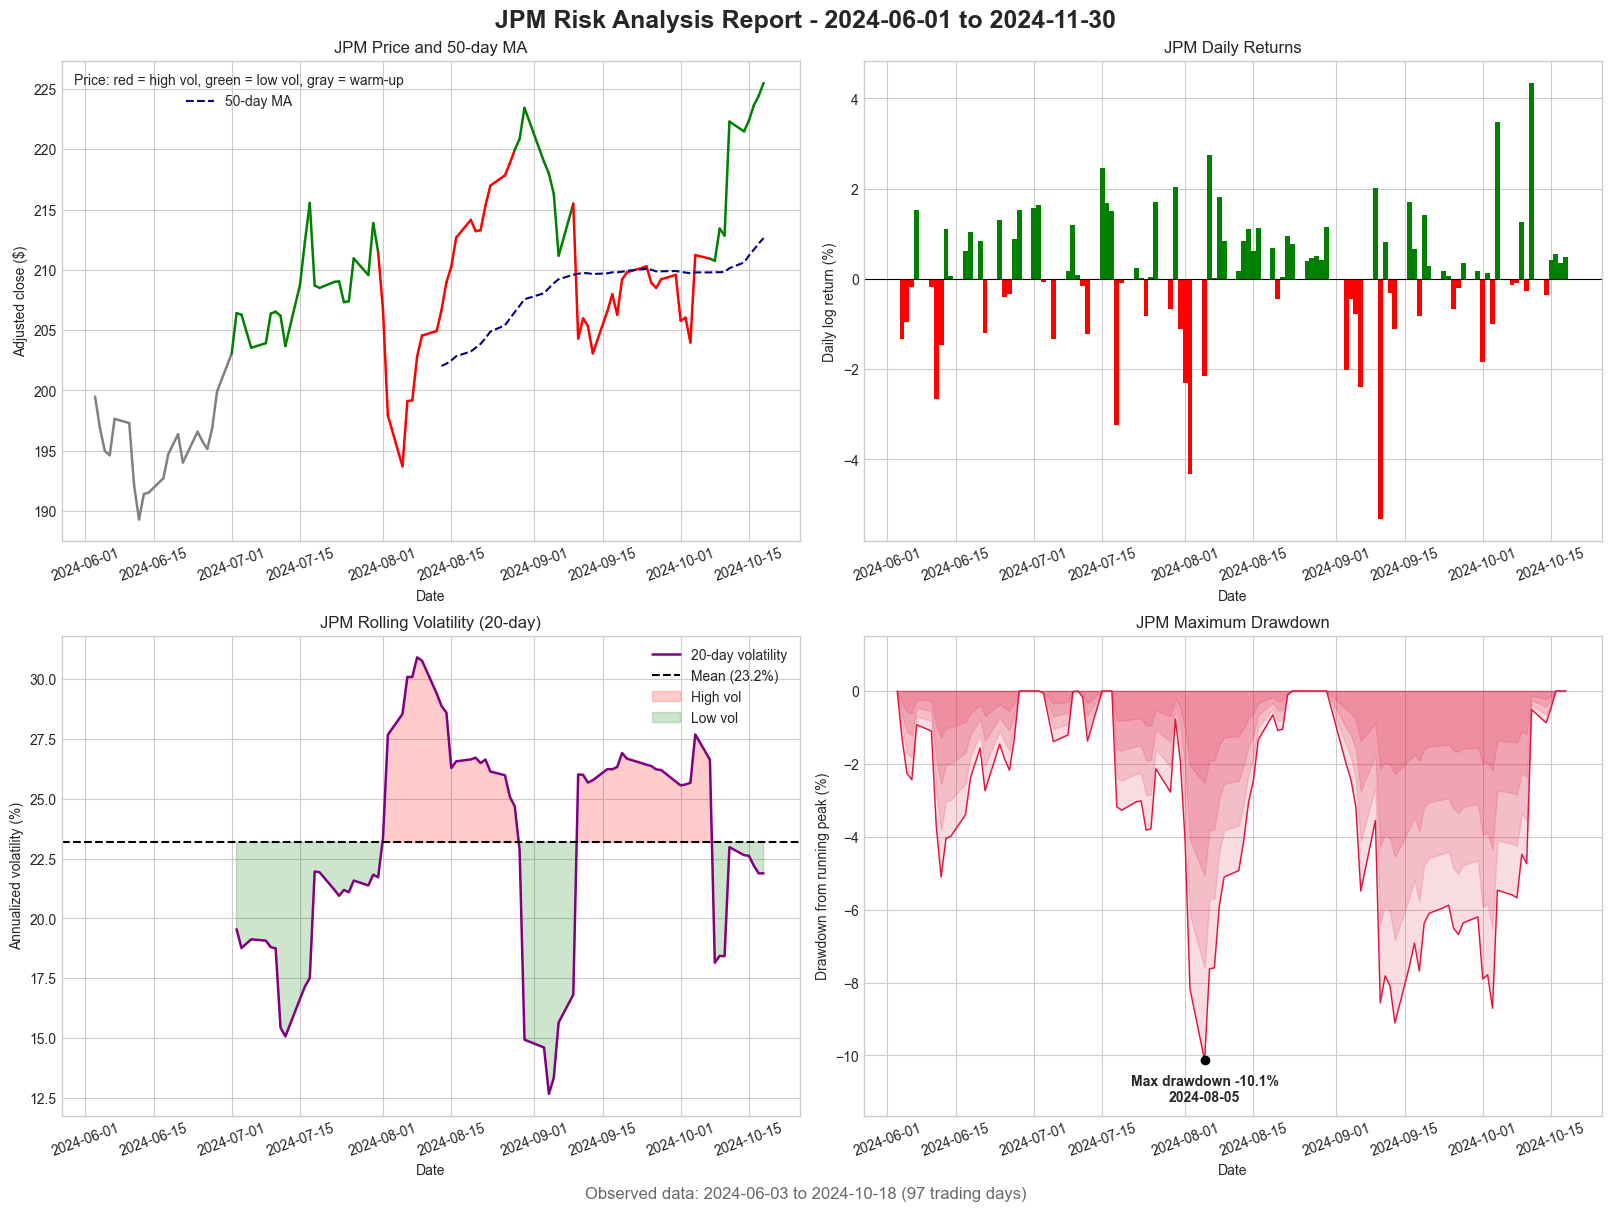

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharex=True, layout='constrained')
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=18, fontweight='bold')
fig.supxlabel(f'Observed data: {first_date} to {last_date} ({len(df)} trading days)', color='dimgray')
mean_volatility = df['volatility'].mean()

# top left: each segment is red/green by its ending date's volatility vs the mean; gray = warm-up
for i in range(1, len(df)):
    vol = df['volatility'].iloc[i]
    color = 'gray' if pd.isna(vol) else ('red' if vol > mean_volatility else 'green')
    axes[0, 0].plot(df.index[i-1:i+1], df['adj_close'].iloc[i-1:i+1], color=color, linewidth=1.8)
ma_label = '50-day MA' if df['sma_50'].notna().any() else '50-day MA (unavailable: fewer than 50 prices)'
axes[0, 0].plot(df.index, df['sma_50'], color='navy', linestyle='--', linewidth=1.5, label=ma_label)
axes[0, 0].set(title=f'{ticker} Price and 50-day MA', ylabel='Adjusted close ($)')
axes[0, 0].legend(title='Price: red = high vol, green = low vol, gray = warm-up')

# top right: daily log returns
axes[0, 1].bar(df.index, df['log_return'] * 100, width=1,
               color=np.where(df['log_return'].ge(0), 'green', 'red'))
axes[0, 1].axhline(0, color='black', linewidth=0.8)
axes[0, 1].set(title=f'{ticker} Daily Returns', ylabel='Daily log return (%)')

# bottom left: rolling volatility, shaded above (red) and below (green) its mean
vol_pct = df['volatility'] * 100
axes[1, 0].plot(df.index, vol_pct, color='purple', linewidth=1.8, label=f'{volatility_window}-day volatility')
axes[1, 0].axhline(mean_volatility * 100, color='black', linestyle='--', label=f'Mean ({mean_volatility:.1%})')
for condition, color, label in [(df['volatility'] > mean_volatility, 'red', 'High vol'),
                                (df['volatility'] < mean_volatility, 'green', 'Low vol')]:
    axes[1, 0].fill_between(df.index, vol_pct, mean_volatility * 100, where=condition,
                            color=color, alpha=0.2, interpolate=True, label=label)
axes[1, 0].set(title=f'{ticker} Rolling Volatility ({volatility_window}-day)', ylabel='Annualized volatility (%)')
axes[1, 0].legend()

# bottom right: drawdown area; layered transparent fills make the red/pink gradient
drawdown_pct = df['drawdown'] * 100
for fraction in [1.0, 0.75, 0.5, 0.25]:
    axes[1, 1].fill_between(df.index, drawdown_pct * fraction, 0, color='crimson', alpha=0.15)
axes[1, 1].plot(df.index, drawdown_pct, color='crimson', linewidth=1)
worst_date = df['drawdown'].idxmin()
axes[1, 1].scatter([worst_date], [drawdown_pct.loc[worst_date]], color='black', zorder=3)
axes[1, 1].annotate(f'Max drawdown {drawdown_pct.loc[worst_date]:.1f}%\n{worst_date.date()}',
                    (worst_date, drawdown_pct.loc[worst_date]), xytext=(0, -10), textcoords='offset points',
                    ha='center', va='top', fontweight='bold')
axes[1, 1].margins(y=0.15)
axes[1, 1].set(title=f'{ticker} Maximum Drawdown', ylabel='Drawdown from running peak (%)')

for ax in axes.flat:
    ax.set_xlabel('Date')
    ax.grid(True)
    ax.tick_params(axis='x', labelrotation=20, labelbottom=True)
plt.show()

## 2.5 Summary Statistics Table
The metrics are glued with scrapbook so `03_run_all_stocks.py` can collect them from each executed report without recalculating.

In [12]:
returns = df['log_return'].dropna()
stats = {
    'ticker': ticker,
    'start_date': start_date,
    'end_date': end_date,
    'first_date': first_date,
    'last_date': last_date,
    'trading_days': len(df),
    'total_return': df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1,
    'annualized_return': np.exp(returns.sum() * 252 / len(returns)) - 1,
    'annualized_volatility': returns.std() * np.sqrt(252),
    'sharpe_ratio': sharpe_ratio,
    'max_drawdown': df['drawdown'].min(),
    'best_day': returns.max(),
    'worst_day': returns.min(),
    'positive_days': returns.gt(0).sum() / len(returns),  # zero-return days stay in the denominator
    'avg_up_day': returns[returns > 0].mean(),  # NaN when there are no up days
    'avg_down_day': returns[returns < 0].mean(),
    'avg_daily_return': returns.mean(),
    'avg_volatility': df['volatility'].mean(),
}
for name, value in stats.items():
    sb.glue(name, value.item() if isinstance(value, np.generic) else value)

In [13]:
def format_metric(value, spec):
    """Format a fraction for display only and output N/A when undefined."""
    return 'N/A' if pd.isna(value) else format(value, spec)

rows = [('Total Return', 'total_return', '+.2%'), ('Annualized Return', 'annualized_return', '+.2%'),
        ('Annualized Volatility', 'annualized_volatility', '.2%'), ('Sharpe Ratio', 'sharpe_ratio', '.2f'),
        ('Maximum Drawdown', 'max_drawdown', '.2%'), ('Best Day', 'best_day', '+.2%'),
        ('Worst Day', 'worst_day', '+.2%'), ('Positive Days', 'positive_days', '.1%'),
        ('Average Up Day', 'avg_up_day', '+.2%'), ('Average Down Day', 'avg_down_day', '+.2%')]
summary_table = pd.DataFrame([(label, format_metric(stats[name], spec)) for label, name, spec in rows],
                             columns=['Metric', 'Value']).set_index('Metric')
print(f'{ticker} summary, observed {first_date} to {last_date} ({len(df)} prices, {len(returns)} returns)')
display(summary_table)

JPM summary, observed 2024-06-03 to 2024-10-18 (97 prices, 96 returns)


,Value
Metric,
Total Return,+13.04%
Annualized Return,+37.95%
Annualized Volatility,23.14%
Sharpe Ratio,1.30
Maximum Drawdown,-10.13%
Best Day,+4.34%
Worst Day,-5.33%
Positive Days,60.4%
Average Up Day,+0.98%
